# Bölüm 12 – Makale Yeniden Üretimi: Koşullu Alt Gruplarla Ceteris Paribus

**Öğrenci:** Serap Şahin (20269348009)

**Makale:** Molnar, C., König, G., Bischl, B. ve Casalicchio, G. (2024). *Model-agnostic Feature Importance and Effects
with Dependent Features: A Conditional Subgroup Approach.* Data Mining and Knowledge Discovery, 38(5), 2903–2941.
doi:10.1007/s10618-022-00901-9 · arXiv:2006.04628 · Yazarların kodu (R): github.com/christophM/paper_conditional_subgroups

**İzlencedeki tip:** Seçenek 2 (Kıyaslama: standart CP ile alt grup CP'si). Makale yeni bir varyant önerdiği için
Seçenek 3 ile de ilişkili; ancak katkısı hız veya stabilite değil, veri bölgesinin dışına düşen sorguları azaltmak.

**Ana soru:** Ceteris paribus profili "diğer her şey sabitken" bir özniteliği değiştirir. Öznitelikler birbirine bağlıysa
bu, gerçekte olmayan veri noktaları üretir ve model bu noktalarda **ekstrapolasyon** yapar. Makale, özniteliği yalnızca
**diğer özniteliklere göre kurulan alt grupların kendi değer aralığında** değiştirmeyi öneriyor.

**Makale PDP üzerinden anlatıyor, ben neden CP'ye uyguluyorum?** Makale yöntemi PDP ve öznitelik önemi (PFI) için
sunuyor. Ama PDP, tek tek CP profillerinin ortalamasıdır ve ekstrapolasyon her bir profilde ortaya çıkar. Yöntemde
alt grup zaten **her gözlem için ayrı** belirleniyor; yazarların kodunda da tek gözlemli profilleri işaretleyen bir
fonksiyon var (`R/highlighted_ice.R`). Bu defterde yöntemi **tek gözlem, yani CP düzeyinde** uyguluyorum. PDP yalnızca
Kısım 4b'de, makalenin kendi şeklini yeniden ürettiğim yerde geçiyor.

**Defterin akışı**

| Kısım | İçerik | Düzey | Derste |
|---|---|---|---|
| 1 | Makalenin motivasyon örneği: tek gözlemin CP yolu üçgen biçimli verinin dışına taşıyor | CP | Hazır |
| 2 | Makalenin alt grup çizimi: alt gruplar ekstrapolasyonu nasıl azaltır? | Veri | Hazır |
| 3 | **Yöntemi sıfırdan yazmak:** alt grup ağacı + alt grup CP profili; motivasyon örneğinde kontrol | CP | 🔴 **Canlı** |
| 4 | Makalenin bisiklet uygulaması: bağımlılık tablosu (4a), makalenin cs-PDP şekli (4b), tek bir kış günü (4c) | PDP + CP | Hazır |
| 5 | **Kendi verim:** Telco müşterisi `5949-XIKAE`. Naif, elle düzeltilmiş ve alt grup CP'si; çok müşteride vurgulu CP | CP | 🔴 **Canlı** |
| 6 | Ağaç derinliğine göre veri dışı nokta oranı (her müşterinin CP profili) | CP | Hazır |
| 7 | Sınırlamalar | – | Tartışma |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (HistGradientBoostingClassifier, RandomForestClassifier,
                              RandomForestRegressor)
from sklearn.metrics import mean_absolute_error, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor, export_text

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#EBEBEB",
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})

# veri.csv = Telco. veri_bisiklet.csv = makalenin deposundaki bisiklet verisi (derste internet gerekmesin diye klasörde).
# Bir dosya bulunamazsa aynı sabit sürüm GitHub'dan indirilir.
from pathlib import Path

VERI = {
    "telco": ("veri.csv",
              "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
              "d5371f5d83a446ad5673cbcca3b814b926491f8a/data/Telco-Customer-Churn.csv"),
    "bike": ("veri_bisiklet.csv",
             "https://raw.githubusercontent.com/christophM/paper_conditional_subgroups/"
             "0fa3386f52f7603c82ebc43b4fd76b7513f5f6b3/data/bike-sharing-daily.csv"),
}


SEKIL = Path("sekiller")
SEKIL.mkdir(exist_ok=True)


def goster(fig, ad):
    """Grafiği sunumda kullanmak için sekiller/ klasörüne kaydeder ve gösterir."""
    fig.savefig(SEKIL / ad, dpi=150, bbox_inches="tight")
    plt.show()


def veri_oku(ad):
    dosya, url = VERI[ad]
    return pd.read_csv(dosya if Path(dosya).exists() else url)
NAIF, ALTGRUP, ELLE = "#d62728", "#1f77b4", "#2ca02c"

## 1. Makalenin motivasyon örneği

Makalenin giriş şekli (`experiments/examples-motivation.R`): $x_1 \sim U(0,1)$, $x_2 \sim U(0, 1-x_1)$. Veri
$x_1 + x_2 \le 1$ üçgeninde. Model doğrudan gerçek fonksiyon: $f(x) = e^{x_1 + x_2}$.

Bir gözlemin CP profili $x_2$'yi sabit tutup $x_1$'i 0'dan 1'e kadar değiştirir. $x_2$ büyük bir gözlemde bu yol
kısa sürede üçgenin dışına, yani verinin hiç olmadığı bölgeye çıkar. (Makale aynı şeyi PDP ile gösteriyor; PDP bu
profillerin ortalaması olduğu için sorun her bir profilden gelir.)

**Not:** Bu örnekte öğrenilmiş bir model yok; tahmin olarak gerçek fonksiyon $e^{x_1+x_2}$ kullanılıyor. Bu yüzden
burada tahmin **hatası** yok. Gösterilen şey yalnızca CP sorgularının veri bölgesinin dışına çıkması. Öğrenilmiş bir
modelde bu bölgedeki tahminler veriyle desteklenmez.

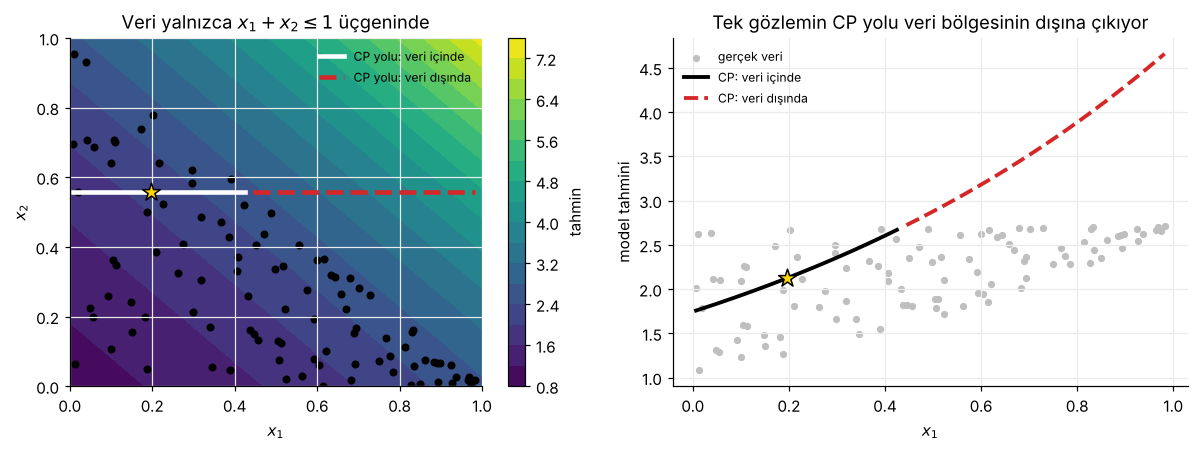

Seçilen gözlem: x1 = 0.20, x2 = 0.56. CP yolunun %56'i üçgenin dışında.
100 gözlemin tamamında CP noktalarının ortalama %27'i üçgenin dışında.


In [2]:
rng = np.random.default_rng(2)
n = 100
x1 = rng.uniform(size=n)
x2 = rng.uniform(0, 1 - x1)
f = lambda a, b: np.exp(a + b)
y = f(x1, x2)

izgara = np.linspace(x1.min(), x1.max(), 50)
i = int(np.argmin(np.abs(x1 - 0.2) + np.abs(x2 - 0.6)))  # x2'si büyük bir gözlem
cp_i = f(izgara, x2[i])
icerde = izgara + x2[i] <= 1

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2))
G1, G2 = np.meshgrid(np.linspace(0, 1, 60), np.linspace(0, 1, 60))
im = a.contourf(G1, G2, f(G1, G2), levels=20, cmap="viridis")
a.scatter(x1, x2, s=18, color="k")
a.plot(izgara[icerde], np.full(icerde.sum(), x2[i]), color="w", lw=3, label="CP yolu: veri içinde")
a.plot(izgara[~icerde], np.full((~icerde).sum(), x2[i]), color=NAIF, lw=3, ls="--", label="CP yolu: veri dışında")
a.scatter(x1[i], x2[i], s=150, marker="*", color="gold", edgecolor="k", zorder=5)
a.set(xlabel="$x_1$", ylabel="$x_2$", title="Veri yalnızca $x_1+x_2 \\leq 1$ üçgeninde")
a.legend(loc="upper right", fontsize=8)
plt.colorbar(im, ax=a, label="tahmin")
b.scatter(x1, y, s=14, color="0.75", label="gerçek veri")
b.plot(izgara[icerde], cp_i[icerde], color="k", lw=2.5, label="CP: veri içinde")
b.plot(izgara[~icerde], cp_i[~icerde], color=NAIF, lw=2.5, ls="--", label="CP: veri dışında")
b.scatter(x1[i], y[i], s=150, marker="*", color="gold", edgecolor="k", zorder=5)
b.set(xlabel="$x_1$", ylabel="model tahmini", title="Tek gözlemin CP yolu veri bölgesinin dışına çıkıyor")
b.legend(fontsize=8)
fig.tight_layout()
goster(fig, "01_ucgen_cp.png")
print(f"Seçilen gözlem: x1 = {x1[i]:.2f}, x2 = {x2[i]:.2f}. CP yolunun %{100 * (~icerde).mean():.0f}'i üçgenin dışında.")
tum_disarida = np.mean([(izgara + x2_l > 1).mean() for x2_l in x2])
print(f"100 gözlemin tamamında CP noktalarının ortalama %{100 * tum_disarida:.0f}'i üçgenin dışında.")

## 2. Alt gruplar ekstrapolasyonu nasıl azaltır? (makalenin alt grup çizimi)

Makalenin `experiments/example-subgroups.R` kurgusu: $x_2 \sim U(0,1)$; $x_2 < 0{,}5$ ise $x_1 \sim N(0,1)$, değilse
$x_1 \sim N(4, 4)$.

* **Sol:** $x_1$ bütün veride karıştırılırsa (CP/PDP'nin yaptığı gibi) yeni noktalar (mavi +) verinin olmadığı yerlere düşer.
* **Sağ:** $x_2 = 0{,}5$'te bölünüp $x_1$ her alt grubun **içinde** karıştırılırsa yeni noktalar verinin üstüne düşer.

Bu kurguda $x_1$ her alt grubun içinde $x_2$'den bağımsız üretildiği için alt grup içinde karıştırma veriyi bozmuyor. Yöntemin fikri bu; gerçek veride ağaç bunu ancak yaklaşık sağlayabilir, garanti etmez.

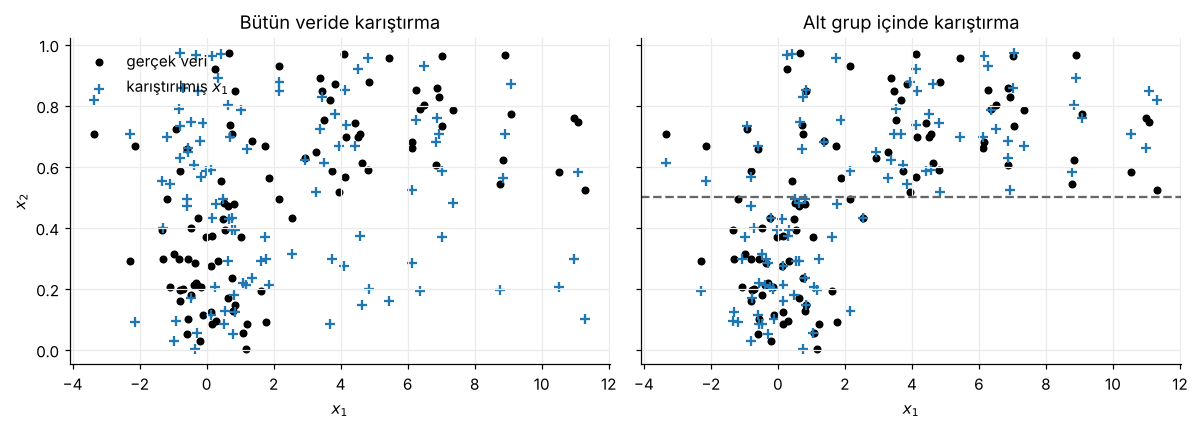

In [3]:
rng = np.random.default_rng(3)
s_x2 = rng.uniform(size=n)
s_x1a, s_x1b = rng.normal(0, 1, n), rng.normal(4, 4, n)
s_x1 = np.where(s_x2 < 0.5, s_x1a, s_x1b)
marjinal = rng.permutation(s_x1)
kosullu = s_x1.copy()
for g in [s_x2 < 0.5, s_x2 >= 0.5]:
    kosullu[g] = rng.permutation(s_x1[g])

fig, eks = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, yeni, baslik in [(eks[0], marjinal, "Bütün veride karıştırma"), (eks[1], kosullu, "Alt grup içinde karıştırma")]:
    ax.scatter(s_x1, s_x2, s=18, color="k", label="gerçek veri")
    ax.scatter(yeni, s_x2, marker="+", s=40, color=ALTGRUP, label="karıştırılmış $x_1$")
    ax.set(xlabel="$x_1$", title=baslik)
eks[1].axhline(0.5, ls="--", color="0.4")
eks[0].set_ylabel("$x_2$")
eks[0].legend(loc="upper left")
fig.tight_layout()
goster(fig, "02_alt_grup_permutasyon.png")

## 3. 🔴 Canlı kodlama: yöntemi sıfırdan yazmak

**Adım 1 – Alt grup ağacı.** İlgilendiğimiz öznitelik $x_j$'yi **diğer özniteliklerden** tahmin eden sığ bir karar
ağacı kurarız. Her yaprak bir alt gruptur $\mathcal{G}_k$. Ağaç $x_j$'yi iyi ayırıyorsa yaprakların içinde
$x_j$'nin dağılımı dardır ve diğer özniteliklere bağımlılığı azalır.

**Adım 2 – Alt grup CP profili.** Gözlem $x^{(i)}$ hangi yaprağa düşüyorsa, profili yalnızca o yapraktaki gerçek
$x_j$ değerlerinin aralığında çizeriz:

$$\text{CP}^{cs}_{i,j}(z) = \hat f\big(z, x^{(i)}_{-j}\big), \qquad z \in \big[\min_{l \in \mathcal{G}_{k(i)}} x^{(l)}_j,\ \max_{l \in \mathcal{G}_{k(i)}} x^{(l)}_j\big]$$

Alt grup PDP'si (cs-PDP) aynı şeyin yaprak içindeki ortalamasıdır.

**Makaleden bir fark:** Makale *transformation tree* (`trtf` paketi) kullanıyor; bu ağaç $x_j$'nin yalnızca ortalamasına
değil bütün dağılımına göre böler. Yazarların kodu CART seçeneğini de destekliyor (`fit_conditionals(type = "cart")`).
Python'da hazır transformation tree olmadığı için CART kullanıyorum ve bunu sınırlamalarda tartışıyorum.
Minimum yaprak büyüklüğü makaledeki gibi 30.

In [4]:
def alt_grup_agaci(X, ozellik, derinlik=2, min_yaprak=30):
    """ozellik'i diğer özniteliklerden tahmin eden ağaç. Yapraklar = alt gruplar."""
    digerleri = X.drop(columns=ozellik)
    kat = digerleri.select_dtypes(exclude="number").columns.tolist()
    on = ColumnTransformer([("kat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), kat)],
                           remainder="passthrough", verbose_feature_names_out=False)
    agac = Pipeline([("on", on), ("agac", DecisionTreeRegressor(max_depth=derinlik, min_samples_leaf=min_yaprak,
                                                                random_state=0))])
    agac.fit(digerleri, X[ozellik])
    return agac


def yaprak(agac, X, ozellik):
    """Her satırın düştüğü yaprağın numarası."""
    Z = agac.named_steps["on"].transform(X.drop(columns=ozellik))
    return agac.named_steps["agac"].apply(Z)


def yaprak_kurali(agac):
    """Her yaprak numarası için okunabilir kural metni, örn. 'season=WINTER & hum<=66.8'."""
    t = agac.named_steps["agac"].tree_
    adlar = list(agac.named_steps["on"].get_feature_names_out())
    kurallar = {}

    def gez(dugum, yol):
        if t.children_left[dugum] == -1:
            kurallar[dugum] = " & ".join(yol) or "tüm veri"
            return
        ad, esik = adlar[t.feature[dugum]], t.threshold[dugum]
        kat = ad.split("_", 1) if (esik == 0.5 and "_" in ad) else None
        sol = f"{kat[0]}≠{kat[1]}" if kat else f"{ad}≤{esik:.2f}"
        sag = f"{kat[0]}={kat[1]}" if kat else f"{ad}>{esik:.2f}"
        gez(t.children_left[dugum], yol + [sol])
        gez(t.children_right[dugum], yol + [sag])

    gez(0, [])
    return kurallar


def cs_cp_profili(tahmin_fn, x, ozellik, agac, X_ref, K=50, tamsayi=False):
    """Tek gözlem için alt grup CP profili: ızgara, gözlemin yaprağındaki gerçek değer aralığıdır."""
    k = yaprak(agac, x, ozellik)[0]
    degerler = X_ref.loc[yaprak(agac, X_ref, ozellik) == k, ozellik]
    if tamsayi:
        iz = np.arange(int(degerler.min()), int(degerler.max()) + 1)
    else:
        iz = np.linspace(degerler.min(), degerler.max(), K)
    kopya = pd.concat([x] * len(iz), ignore_index=True)
    kopya[ozellik] = iz
    return iz, np.asarray(tahmin_fn(kopya)), kopya


def cs_pdp(tahmin_fn, X, ozellik, agac, K=30):
    """Her yaprak için o yaprağın aralığında PDP. Sözlük: yaprak -> (ızgara, pdp, gözlem sayısı)."""
    yap = yaprak(agac, X, ozellik)
    sonuc = {}
    for k in np.unique(yap):
        alt = X[yap == k]
        iz = np.linspace(alt[ozellik].min(), alt[ozellik].max(), K)
        pd_ = []
        for z in iz:
            kopya = alt.copy()
            kopya[ozellik] = z
            pd_.append(np.mean(tahmin_fn(kopya)))
        sonuc[k] = (iz, np.array(pd_), len(alt))
    return sonuc

**Kontrol: motivasyon örneğinde alt grup CP'si.** $x_1$'i $x_2$'den tahmin eden ağaç, üçgeni $x_2$'ye göre yatay
dilimlere böler. Her gözlemin CP profili artık yalnızca kendi diliminde gerçekten görülen $x_1$ aralığında çizilir.
Üç gözlem için naif ve alt grup CP yollarını karşılaştırıyorum; sonra 100 gözlemin hepsi için üçgenin dışına düşen
CP noktalarını sayıyorum.

Alt gruplar: ['x2≤0.17 & x2≤0.03', 'x2≤0.17 & x2>0.03', 'x2>0.17 & x2≤0.52', 'x2>0.17 & x2>0.52']


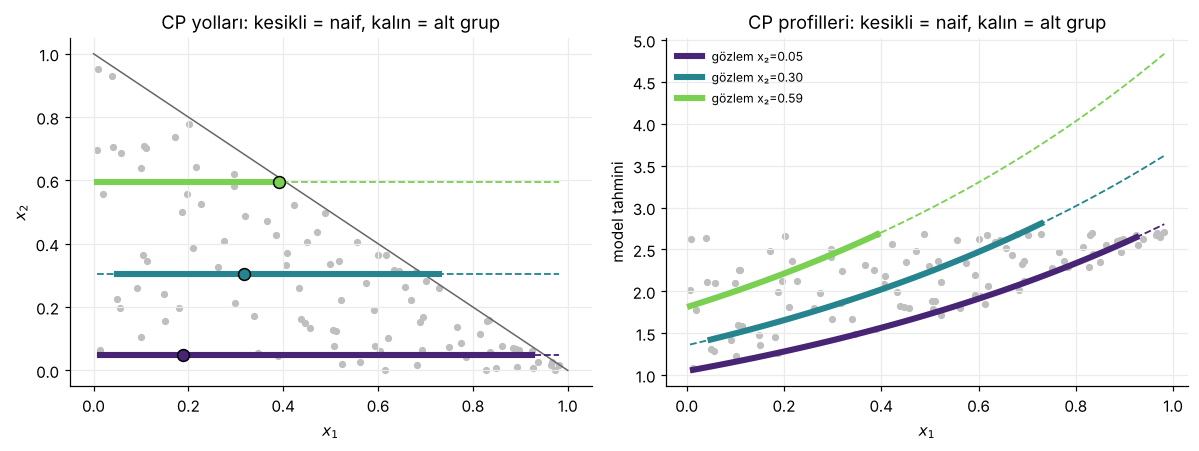

Üçgenin dışına düşen CP noktaları (100 gözlemin ortalaması): naif %27, alt grup %10


In [5]:
D = pd.DataFrame({"x1": x1, "x2": x2})          # Kısım 1'deki veri
tahmin_f = lambda X: np.exp(X["x1"].to_numpy() + X["x2"].to_numpy())
agac_m = alt_grup_agaci(D, "x1", derinlik=2, min_yaprak=10)
print("Alt gruplar:", list(yaprak_kurali(agac_m).values()))

secilen = [int(np.argmin(np.abs(x2 - h))) for h in (0.05, 0.3, 0.6)]
renkler = plt.cm.viridis(np.linspace(0.1, 0.8, len(secilen)))
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2))
a.scatter(D.x1, D.x2, s=14, color="0.75")
a.plot([0, 1], [1, 0], color="0.4", lw=1)
b.scatter(D.x1, tahmin_f(D), s=14, color="0.75")
for j, r in zip(secilen, renkler):
    x = D.iloc[[j]].reset_index(drop=True)
    iz_cs, y_cs, _ = cs_cp_profili(tahmin_f, x, "x1", agac_m, D)
    a.plot(izgara, np.full_like(izgara, x2[j]), color=r, lw=1.2, ls="--")
    a.plot(iz_cs, np.full_like(iz_cs, x2[j]), color=r, lw=4)
    b.plot(izgara, tahmin_f(x.loc[x.index.repeat(len(izgara))].assign(x1=izgara)), color=r, lw=1.2, ls="--")
    b.plot(iz_cs, y_cs, color=r, lw=4, label=f"gözlem x₂={x2[j]:.2f}")
    a.scatter(x1[j], x2[j], s=60, color=r, edgecolor="k", zorder=5)
a.set(xlabel="$x_1$", ylabel="$x_2$", title="CP yolları: kesikli = naif, kalın = alt grup")
b.set(xlabel="$x_1$", ylabel="model tahmini", title="CP profilleri: kesikli = naif, kalın = alt grup")
b.legend(fontsize=8)
fig.tight_layout()
goster(fig, "03_ucgen_alt_grup_cp.png")

naif_dis, cs_dis = [], []
for j in range(len(D)):
    x = D.iloc[[j]].reset_index(drop=True)
    iz_cs, _, _ = cs_cp_profili(tahmin_f, x, "x1", agac_m, D)
    naif_dis.append((izgara + x2[j] > 1).mean())
    cs_dis.append((iz_cs + x2[j] > 1).mean())
print(f"Üçgenin dışına düşen CP noktaları (100 gözlemin ortalaması): naif %{100 * np.mean(naif_dis):.0f}, "
      f"alt grup %{100 * np.mean(cs_dis):.0f}")

## 4. Makalenin gerçek veri uygulaması: bisiklet kiralama

Makale yöntemi günlük bisiklet kiralama verisinde gösteriyor (`experiments/bike-application.R`). Aynı dosyayı ve aynı
ön işlemeyi kullanıyorum.

* **4a – Tahmin edici bağımlılık tablosu (makalenin tablosu):** Her öznitelik, geri kalanlardan rastgele ormanla tahmin
  edildiğinde kaybın yüzde kaçı açıklanıyor? (İki katlı çapraz doğrulama; sayısal öznitelikte $R^2$, kategoride
  doğruluk tabanlı karşılığı.) Bu tablo, hangi özniteliğin CP profilinde ekstrapolasyon riski taşıdığını gösterir.
* **4b – Sıcaklık için cs-PDP (makalenin şekli, PDP düzeyinde):** derinliği 2 olan alt grup ağacıyla.
* **4c – Tek bir kış gününün sıcaklık CP profili (benim uyarlamam, CP düzeyinde).**

In [6]:
bike = veri_oku("bike")
bike["weekday"] = bike["weekday"].map(dict(enumerate(["SUN", "MON", "TUE", "WED", "THU", "FRI", "SAT"])))
bike["holiday"] = bike["holiday"].map({0: "NO HOLIDAY", 1: "HOLIDAY"})
bike["work"] = bike["workingday"].map({0: "NO WORKING DAY", 1: "WORKING DAY"})
bike["season"] = bike["season"].map({1: "WINTER", 2: "SPRING", 3: "SUMMER", 4: "FALL"})
bike["weather"] = bike["weathersit"].map({1: "GOOD", 2: "BAD", 3: "BAD"})
bike["yr"] = bike["yr"].map({0: "2011", 1: "2012"})
bike["temp"] = (bike["temp"] * (39 - (-8)) + (-8)).round(1)
bike["wind"] = 67 * bike["windspeed"]
bike["hum"] = (100 * bike["hum"]).round(3)
BIKE_OZ = ["season", "yr", "holiday", "weekday", "temp", "hum", "work", "weather", "wind"]
bike = bike[BIKE_OZ + ["cnt"]]
print(bike.shape)
print(f"corr(temp, hum) = {bike.temp.corr(bike.hum):.2f}   (makale: 0.13)")

(731, 10)
corr(temp, hum) = 0.13   (makale: 0.13)


In [7]:
def tahmin_edici_bagimlilik(X, ozellik, rng_seed=2):
    """Makaledeki ölçü: ozellik'i diğerlerinden RF ile tahmin et, iki katın ortalama 'açıklanan kayıp' oranı."""
    rng = np.random.default_rng(rng_seed)
    ind1 = rng.choice(len(X), size=len(X) // 2, replace=False)
    ind2 = np.setdiff1d(np.arange(len(X)), ind1)
    diger = X.drop(columns=ozellik)
    kat = diger.select_dtypes(exclude="number").columns.tolist()
    sayisal = pd.api.types.is_numeric_dtype(X[ozellik])
    skorlar = []
    for egit, test in [(ind1, ind2), (ind2, ind1)]:
        on = ColumnTransformer([("kat", OneHotEncoder(handle_unknown="ignore"), kat)], remainder="passthrough")
        rf = (RandomForestRegressor if sayisal else RandomForestClassifier)(n_estimators=500, random_state=0, n_jobs=-1)
        m = Pipeline([("on", on), ("rf", rf)]).fit(diger.iloc[egit], X[ozellik].iloc[egit])
        tahmin, gercek = m.predict(diger.iloc[test]), X[ozellik].iloc[test]
        if sayisal:
            sse, sst = ((tahmin - gercek) ** 2).sum(), ((gercek - gercek.mean()) ** 2).sum()
        else:
            mod_sinif = X[ozellik].iloc[egit].mode()[0]
            sst, sse = 1 - (gercek == mod_sinif).mean(), 1 - (tahmin == gercek).mean()
        skorlar.append(1 - sse / sst)
    return np.mean(skorlar)


MAKALE_TABLO = {"season": 45, "yr": 8, "holiday": 29, "weekday": 14, "temp": 66, "hum": 43, "work": 100,
                "weather": 46, "wind": 12}
tablo = pd.DataFrame({"makale (%)": MAKALE_TABLO,
                      "yeniden üretim (%)": {o: round(100 * abs(tahmin_edici_bagimlilik(bike[BIKE_OZ], o)))
                                             for o in BIKE_OZ}})
print(tablo.T.to_string())

                    season  yr  holiday  weekday  temp  hum  work  weather  wind
makale (%)              45   8       29       14    66   43   100       46    12
yeniden üretim (%)      45   2       72       17    67   38   100       38     6


In [8]:
rng = np.random.default_rng(2)
egit_id = rng.choice(len(bike), size=int(0.7 * len(bike)), replace=False)
test_id = np.setdiff1d(np.arange(len(bike)), egit_id)
b_egit, b_test = bike.iloc[egit_id], bike.iloc[test_id]
KAT_B = bike[BIKE_OZ].select_dtypes(exclude="number").columns.tolist()
bike_model = Pipeline([("on", ColumnTransformer([("kat", OneHotEncoder(handle_unknown="ignore"), KAT_B)],
                                                remainder="passthrough")),
                       ("rf", RandomForestRegressor(n_estimators=500, random_state=0, n_jobs=-1))])
bike_model.fit(b_egit[BIKE_OZ], b_egit["cnt"])
print(f"Test MAE = {mean_absolute_error(b_test['cnt'], bike_model.predict(b_test[BIKE_OZ])):.1f}   (makale: 522.2)")
f_bike = lambda X: bike_model.predict(X[BIKE_OZ])

Test MAE = 541.5   (makale: 522.2)


### 4b – Makalenin şekli: sıcaklık için cs-PDP

Makale bu uygulamada sonucu PDP düzeyinde gösteriyor; burada o şekli yeniden üretiyorum. Kısım 4c'de aynı alt grup
ağacını tek bir günün CP profiline uyguluyorum.

|--- season_SUMMER <= 0.50
|   |--- season_WINTER <= 0.50
|   |   |--- value: [14.60]
|   |--- season_WINTER >  0.50
|   |   |--- value: [5.73]
|--- season_SUMMER >  0.50
|   |--- hum <= 66.81
|   |   |--- value: [26.25]
|   |--- hum >  66.81
|   |   |--- value: [23.57]



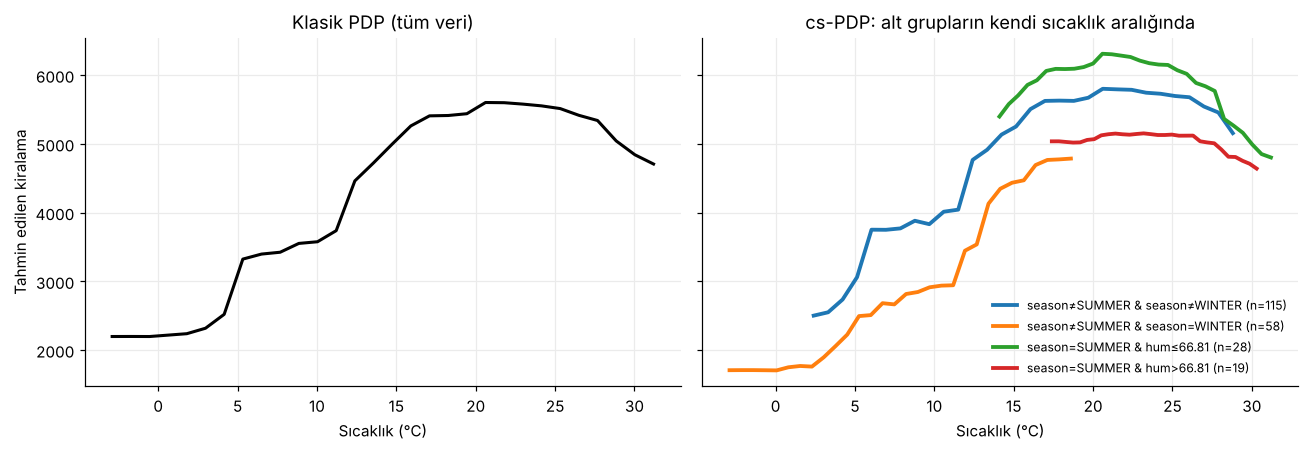

In [9]:
agac_temp = alt_grup_agaci(b_egit[BIKE_OZ], "temp", derinlik=2, min_yaprak=30)
print(export_text(agac_temp.named_steps["agac"],
                  feature_names=list(agac_temp.named_steps["on"].get_feature_names_out())))
cs = cs_pdp(f_bike, b_test[BIKE_OZ], "temp", agac_temp)
iz = np.linspace(b_test.temp.min(), b_test.temp.max(), 30)
pdp = [f_bike(b_test[BIKE_OZ].assign(temp=z)).mean() for z in iz]

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
a.plot(iz, pdp, color="k", lw=2)
a.set(xlabel="Sıcaklık (°C)", ylabel="Tahmin edilen kiralama", title="Klasik PDP (tüm veri)")
kural = yaprak_kurali(agac_temp)
for k, (izk, pk, nk) in cs.items():
    b.plot(izk, pk, lw=2.5, label=f"{kural[k]} (n={nk})")
b.set(xlabel="Sıcaklık (°C)", title="cs-PDP: alt grupların kendi sıcaklık aralığında")
b.legend(fontsize=8)
fig.tight_layout()
goster(fig, "04_bisiklet_cs_pdp.png")

**Yorum.**

* **Tablo:** Sıcaklık, kaybının yaklaşık üçte ikisi diğer özniteliklerden açıklanabilen öznitelik; yani CP/PDP'de en çok
  ekstrapolasyon riski taşıyanlardan biri. `season`, `temp`, `hum` ve `work` makaledekiyle çok yakın çıktı. Farklar:
  `holiday` (%72 / %29): tatil günü, "hafta içi olup iş günü olmayan gün" olarak `weekday` ve `work`'ten neredeyse
  kesin çıkarılabiliyor; Python'daki rastgele orman bunu yakalıyor, makaledeki R `randomForest` daha az yakalamış
  olabilir. `yr`, `wind` ve `weather`'daki farklar küçük örneklemde (731 gün, iki kat) beklenebilecek düzeyde.
* **Model:** Test MAE makaleye yakın (rastgele orman uygulaması ve bölme farklı).
* **Alt grup ağacı:** Sıcaklığı tahmin eden ağaç önce **mevsime** göre bölüyor. Klasik PDP, kışın 30 °C gibi hiç
  görülmemiş günler için de tahmin alıp ortalıyor. cs-PDP her alt grupta yalnızca o grupta gerçekten görülen
  sıcaklıklar için etki gösteriyor.

### 4c – Tek bir kış günü: sıcaklığın CP profili

Bölüm 12'nin sorusu tek gözlem içindir: *"Bu gün daha sıcak olsaydı kaç bisiklet kiralanırdı?"* Test kümesinden tipik
bir kış günü seçiyorum (kış günleri arasında sıcaklığı medyana en yakın olan). Naif CP sıcaklığı bütün yılın
aralığında (yaklaşık −3 °C ile 31 °C) değiştirir; alt grup CP'si yalnızca bu günün alt grubunda görülen sıcaklıklarda.

season   yr    holiday weekday  temp    hum        work weather     wind
WINTER 2011 NO HOLIDAY     WED   5.9 77.542 WORKING DAY     BAD 14.75005


Alt grup: season≠SUMMER & season=WINTER; alt grup CP aralığı -5.2–18.9 °C
Eğitim verisinde kışın görülen en yüksek sıcaklık 18.9 °C; naif CP 32.5 °C'ye kadar gidiyor.


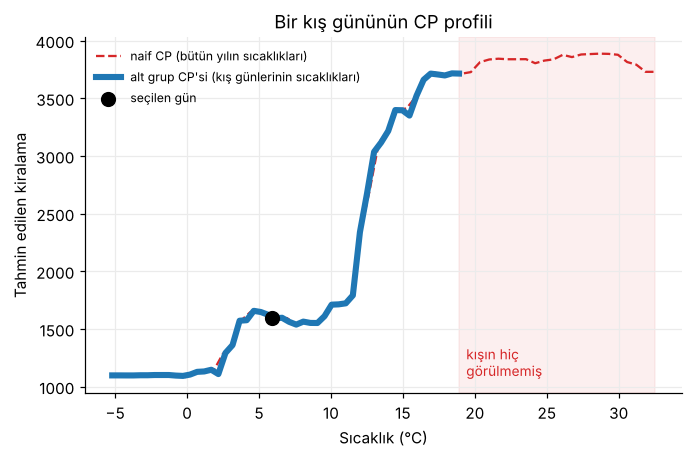

In [10]:
kis = b_test[b_test.season == "WINTER"]
gun = kis.iloc[[int(np.argmin(np.abs(kis.temp - kis.temp.median())))]][BIKE_OZ].reset_index(drop=True)
print(gun.to_string(index=False))
iz_gun = np.linspace(b_egit.temp.min(), b_egit.temp.max(), 60)
cp_naif = f_bike(gun.loc[gun.index.repeat(len(iz_gun))].assign(temp=iz_gun))
iz_cs, y_cs, _ = cs_cp_profili(f_bike, gun, "temp", agac_temp, b_egit[BIKE_OZ])
kis_max = b_egit.loc[b_egit.season == "WINTER", "temp"].max()
print(f"Alt grup: {yaprak_kurali(agac_temp)[yaprak(agac_temp, gun, 'temp')[0]]}; "
      f"alt grup CP aralığı {iz_cs.min():.1f}–{iz_cs.max():.1f} °C")
print(f"Eğitim verisinde kışın görülen en yüksek sıcaklık {kis_max:.1f} °C; naif CP {iz_gun.max():.1f} °C'ye kadar gidiyor.")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(iz_gun, cp_naif, color=NAIF, lw=1.5, ls="--", label="naif CP (bütün yılın sıcaklıkları)")
ax.plot(iz_cs, y_cs, color=ALTGRUP, lw=4, label="alt grup CP'si (kış günlerinin sıcaklıkları)")
ax.axvspan(kis_max, iz_gun.max(), color=NAIF, alpha=0.07)
ax.text(kis_max + 0.5, ax.get_ylim()[0] + 150, "kışın hiç\ngörülmemiş", color=NAIF, fontsize=9)
ax.scatter(gun.temp, f_bike(gun), s=80, color="k", zorder=5, label="seçilen gün")
ax.set(xlabel="Sıcaklık (°C)", ylabel="Tahmin edilen kiralama", title="Bir kış gününün CP profili")
ax.legend(fontsize=8)
goster(fig, "05_kis_gunu_cp.png")

## 5. 🔴 Canlı kodlama: kendi verim, Telco müşterisi `5949-XIKAE`

Bölüm 12 uygulamamda bu müşteri için `tenure` (abonelik süresi) profilini çizmiştim. Sorun: `TotalCharges ≈ tenure ×
MonthlyCharges`. `tenure` 0–72 ay arasında değişirken `TotalCharges` sabit kalınca, CP noktalarının **%90**'ı en yakın
gerçek müşteriden uzak düşüyordu. Uygulamada bunu ilişkiyi **elle** yazarak düzeltmiştim ("tutarlı CP").

**Makalenin katkısı:** İlişkiyi bilmeden, veriden öğrenmek. Ağaç `tenure`'u diğer özniteliklerden tahmin ederken
`TotalCharges` ve `MonthlyCharges` üzerinden bölecek. Karşılaştıracağım üç profil:

| Profil | `tenure` aralığı | Bilgi kaynağı |
|---|---|---|
| Naif CP | 0–72 ay, `TotalCharges` sabit | Hiçbiri (kitaptaki CP) |
| Elle düzeltilmiş CP | 0–72 ay, `TotalCharges` yeniden hesaplanır | Alan bilgisi (uygulamam) |
| **Alt grup CP'si** | Müşterinin yaprağındaki gerçek `tenure` aralığı | **Veriden öğrenilir (makale)** |

In [11]:
tel = veri_oku("telco").set_index("customerID")
tel["TotalCharges"] = pd.to_numeric(tel["TotalCharges"], errors="coerce").fillna(0.0)
tel["Churn"] = (tel["Churn"] == "Yes").astype(int)
T_SAY = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
T_KAT = [c for c in tel.columns if c not in T_SAY + ["Churn"]]
T_OZ = T_SAY + T_KAT

# Bölüm 12 uygulamasıyla aynı bölme ve model
MUSTERI_ID = "5949-XIKAE"
t_egitim, t_test = train_test_split(tel.drop(index=MUSTERI_ID), train_size=2 / 3, random_state=42,
                                   stratify=tel.drop(index=MUSTERI_ID)["Churn"])
t_test = pd.concat([tel.loc[[MUSTERI_ID]], t_test])
gb = Pipeline([("on", ColumnTransformer([("kat", OneHotEncoder(handle_unknown="ignore"), T_KAT),
                                         ("say", StandardScaler(), T_SAY)], sparse_threshold=0)),
               ("m", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                                    l2_regularization=1.0, random_state=42))])
gb.fit(t_egitim[T_OZ], t_egitim["Churn"])
print(f"Test ROC-AUC = {roc_auc_score(t_test['Churn'], gb.predict_proba(t_test[T_OZ])[:, 1]):.3f}")
p_churn = lambda D: gb.predict_proba(D[T_OZ])[:, 1]
musteri = t_test.loc[[MUSTERI_ID], T_OZ].reset_index(drop=True)
print(musteri[["tenure", "MonthlyCharges", "TotalCharges", "Contract", "InternetService"]].to_string(index=False))
print(f"P(ayrılma) = {p_churn(musteri)[0]:.2f}")

# Bölüm 12 uygulamasındaki gerçekçilik testi: 3 sayısal öznitelik standartlaştırılır, eğitim verisindeki en yakın komşu
# uzaklıklarının %99 kantili eşiktir. Eşiği aşan nokta "veri dışı" sayılır.
GERCEK_OZ = ["tenure", "MonthlyCharges", "TotalCharges"]
olcek = StandardScaler().fit(t_egitim[GERCEK_OZ])
ref = olcek.transform(t_egitim[GERCEK_OZ])
nn = NearestNeighbors(n_neighbors=2).fit(ref)
tau = np.quantile(nn.kneighbors(ref)[0][:, 1], 0.99)
veri_disi = lambda D: nn.kneighbors(olcek.transform(D[GERCEK_OZ]), n_neighbors=1)[0][:, 0] > tau

Test ROC-AUC = 0.840
 tenure  MonthlyCharges  TotalCharges       Contract InternetService
      8           83.55        680.05 Month-to-month     Fiber optic
P(ayrılma) = 0.62


In [12]:
# 🔴 Canlı: alt grup ağacını kur ve müşterinin yaprağına bak
agac_tenure = alt_grup_agaci(t_egitim[T_OZ], "tenure", derinlik=3, min_yaprak=30)
print(export_text(agac_tenure.named_steps["agac"],
                  feature_names=list(agac_tenure.named_steps["on"].get_feature_names_out()), decimals=1))
k = yaprak(agac_tenure, musteri, "tenure")[0]
yaprak_tenure = t_egitim.loc[yaprak(agac_tenure, t_egitim[T_OZ], "tenure") == k, "tenure"]
print(f"Müşterinin alt grubu: {yaprak_kurali(agac_tenure)[k]}")
print(f"Müşterinin yaprağı: {k}, yapraktaki müşteri sayısı: {len(yaprak_tenure)}, "
      f"tenure aralığı: {yaprak_tenure.min()}–{yaprak_tenure.max()} ay")

|--- TotalCharges <= 970.7
|   |--- TotalCharges <= 387.3
|   |   |--- TotalCharges <= 174.5
|   |   |   |--- value: [2.1]
|   |   |--- TotalCharges >  174.5
|   |   |   |--- value: [7.9]
|   |--- TotalCharges >  387.3
|   |   |--- MonthlyCharges <= 30.8
|   |   |   |--- value: [31.1]
|   |   |--- MonthlyCharges >  30.8
|   |   |   |--- value: [10.6]
|--- TotalCharges >  970.7
|   |--- TotalCharges <= 3778.2
|   |   |--- MonthlyCharges <= 53.9
|   |   |   |--- value: [55.0]
|   |   |--- MonthlyCharges >  53.9
|   |   |   |--- value: [29.5]
|   |--- TotalCharges >  3778.2
|   |   |--- TotalCharges <= 5704.1
|   |   |   |--- value: [55.7]
|   |   |--- TotalCharges >  5704.1
|   |   |   |--- value: [67.4]

Müşterinin alt grubu: TotalCharges≤970.70 & TotalCharges>387.30 & MonthlyCharges>30.80
Müşterinin yaprağı: 7, yapraktaki müşteri sayısı: 436, tenure aralığı: 4–29 ay


In [13]:
# 🔴 Canlı: üç profili hesapla ve karşılaştır
IZ = np.arange(0, 73)
naif = pd.concat([musteri] * len(IZ), ignore_index=True).assign(tenure=IZ)
oran = musteri["TotalCharges"][0] / (musteri["tenure"][0] * musteri["MonthlyCharges"][0])
elle = naif.assign(TotalCharges=IZ * musteri["MonthlyCharges"][0] * oran)
iz_cs, y_cs, cs_nokta = cs_cp_profili(p_churn, musteri, "tenure", agac_tenure, t_egitim[T_OZ], tamsayi=True)

ozet = pd.DataFrame({
    "tenure aralığı": ["0–72", "0–72", f"{iz_cs.min()}–{iz_cs.max()}"],
    "veri dışı nokta (%)": [100 * veri_disi(naif).mean(), 100 * veri_disi(elle).mean(), 100 * veri_disi(cs_nokta).mean()],
}, index=["Naif CP", "Elle düzeltilmiş CP", "Alt grup CP'si (makale)"]).round(1)
print(ozet.to_string())

# Kontrol: alt grup CP'si yeni bir tahmin üretmez. Ortak tenure değerlerinde naif CP ile aynı tahmini verir;
# değişen yalnızca profilin gösterildiği aralıktır.
ortak = np.isin(IZ, iz_cs)
fark = np.abs(p_churn(naif)[ortak] - y_cs).max()
assert fark < 1e-12
print(f"\nOrtak noktalarda naif CP ile alt grup CP'si arasındaki en büyük fark: {fark:.1f}")

                        tenure aralığı  veri dışı nokta (%)
Naif CP                           0–72                 90.4
Elle düzeltilmiş CP               0–72                  0.0
Alt grup CP'si (makale)           4–29                 73.1

Ortak noktalarda naif CP ile alt grup CP'si arasındaki en büyük fark: 0.0


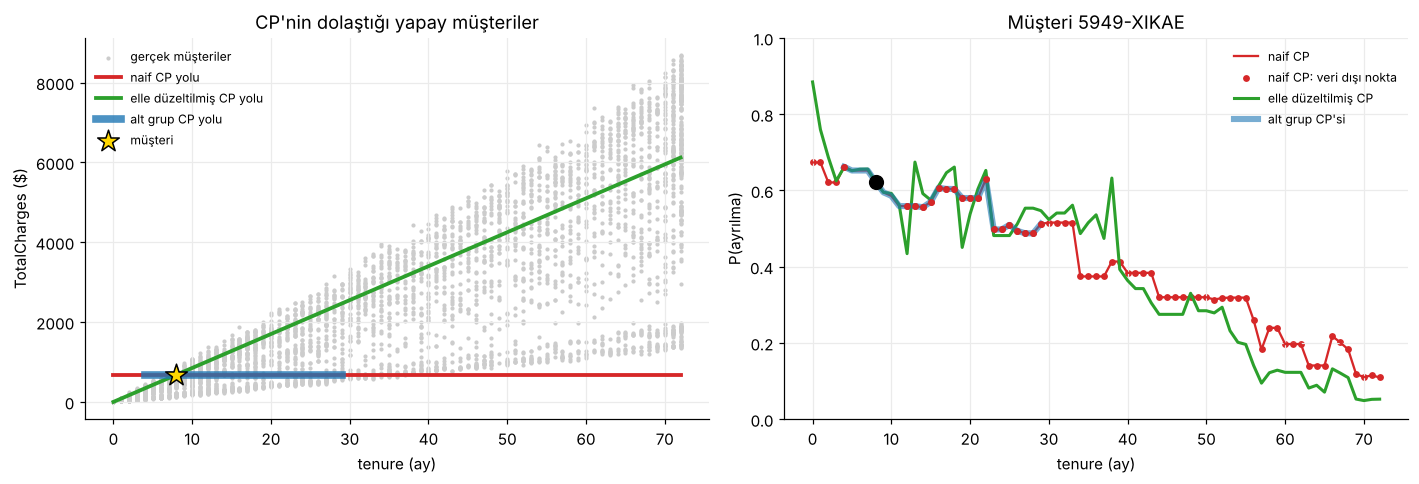

In [14]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.5))
a.scatter(t_egitim.tenure, t_egitim.TotalCharges, s=3, color="0.8", label="gerçek müşteriler")
a.plot(naif.tenure, naif.TotalCharges, color=NAIF, lw=2.5, label="naif CP yolu")
a.plot(elle.tenure, elle.TotalCharges, color=ELLE, lw=2.5, label="elle düzeltilmiş CP yolu")
a.plot(cs_nokta.tenure, cs_nokta.TotalCharges, color=ALTGRUP, lw=5, alpha=0.8, label="alt grup CP yolu")
a.scatter(musteri.tenure, musteri.TotalCharges, s=220, marker="*", color="gold", edgecolor="k", zorder=5, label="müşteri")
a.set(xlabel="tenure (ay)", ylabel="TotalCharges ($)", title="CP'nin dolaştığı yapay müşteriler")
a.legend(fontsize=8)

o = veri_disi(naif)
y_naif = p_churn(naif)
b.plot(IZ, y_naif, color=NAIF, lw=1.5, label="naif CP")
b.scatter(IZ[o], y_naif[o], color=NAIF, s=12, label="naif CP: veri dışı nokta")
b.plot(IZ, p_churn(elle), color=ELLE, lw=2, label="elle düzeltilmiş CP")
b.plot(iz_cs, y_cs, color=ALTGRUP, lw=4, alpha=0.6, label="alt grup CP'si", zorder=2)
o_cs = veri_disi(cs_nokta)
b.scatter(iz_cs[o_cs], y_cs[o_cs], s=12, color=NAIF, zorder=3)
b.scatter(musteri.tenure, p_churn(musteri), s=80, color="k", zorder=5)
b.set(xlabel="tenure (ay)", ylabel="P(ayrılma)", ylim=(0, 1), title=f"Müşteri {MUSTERI_ID}")
b.legend(fontsize=8)
fig.tight_layout()
goster(fig, "06_telco_musteri_cp.png")

**Yorum.** Ağaç `tenure`'u neredeyse yalnızca `TotalCharges` ve `MonthlyCharges` ile bölüyor: ilişkiyi kimse
söylemeden veriden buldu. Müşterinin yaprağında `tenure` 0–72 yerine 4–29 ay; veri dışı nokta oranı düşüyor.

**Önemli ayrım:** Alt grup CP'si tahminleri **düzeltmez**; ortak noktalarda naif CP ile birebir aynı tahmini verir
(yukarıdaki kontrol). Yaptığı şey, profili müşterinin alt grubunda gözlenen aralığa daraltmaktır. Bu, bütün
sorguların gerçekçi olduğunu garanti etmez: daraltılmış aralıktaki noktaların hâlâ %73'ü uzaklık eşiğini aşıyor. Elle düzeltilmiş CP ise
`TotalCharges`'ı da değiştirdiği için **farklı bir soruyu** cevaplar ("süre ve toplam ödeme birlikte değişirse?");
standart CP ile aynı niceliği ölçmez, bu yüzden "en doğru CP" diye sıralanmamalı.

Alt grup CP'si elle düzeltilmiş CP'nin %0'ına inmiyor. Neden? Yaprak `TotalCharges` ve `MonthlyCharges` için **aralıklarla**
tanımlı. Müşterinin `TotalCharges`'ı sabitken `tenure` 4 ay olursa aylık ödemesi ~170 $, 29 ay olursa ~23 $ demektir;
ikisi de bu müşteri için gerçekçi değil. Oransal bir ilişkiyi eksen paralel bölünmelerle ancak kabaca yakalayabiliyoruz.
Bu, makalenin yönteminin bu veri için bir sınırı ve savunmada tartışılacak ana nokta.

### 5b – Vurgulu CP profilleri: birçok müşteri, her biri kendi alt grubunda

Yazarların kodundaki `highlighted_ice` fonksiyonu her gözlemin profilini çizip, alt grup modeline göre olası
kısımları koyu, olası olmayan kısımları silik gösteriyor. Aynı fikri CART ile uyguluyorum: rastgele seçilen 40 test
müşterisinin her biri için naif `tenure` profilini çiziyorum; profilin **müşterinin kendi alt grubundaki** `tenure`
aralığına düşen kısmı koyu, dışındaki kısmı silik. Bu, yöntemin tek tek CP profilleri üzerinde ne yaptığını gösterir.

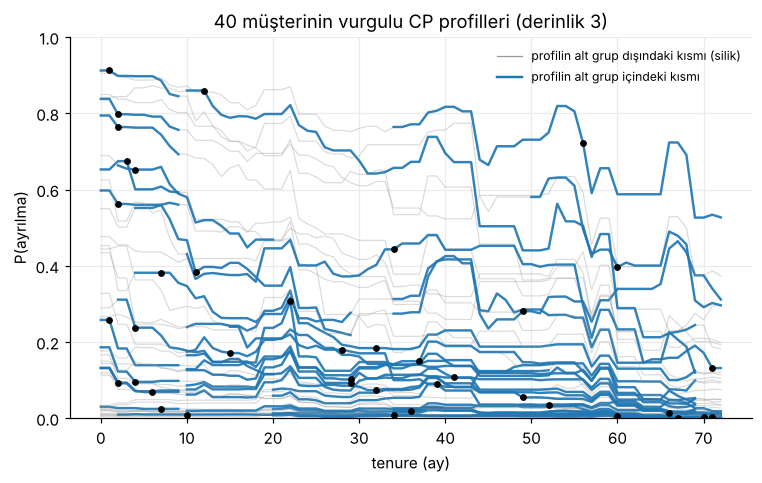

Bu 40 profilde noktaların %51'i müşterinin kendi alt grubunun aralığında; geri kalanı silik.


In [15]:
yap_egit3 = yaprak(agac_tenure, t_egitim[T_OZ], "tenure")
araliklar3 = t_egitim.assign(_y=yap_egit3).groupby("_y")["tenure"].agg(["min", "max"])
ornek = t_test[T_OZ].sample(40, random_state=1).reset_index(drop=True)
yap_ornek = yaprak(agac_tenure, ornek, "tenure")
fig, ax = plt.subplots(figsize=(8, 4.5))
for j in range(len(ornek)):
    x = ornek.iloc[[j]]
    cp_j = p_churn(x.loc[x.index.repeat(len(IZ))].assign(tenure=IZ))
    lo, hi = araliklar3.loc[yap_ornek[j]]
    ic = (IZ >= lo) & (IZ <= hi)
    ax.plot(IZ, cp_j, color="0.6", lw=0.8, alpha=0.35)
    ax.plot(IZ[ic], cp_j[ic], color=ALTGRUP, lw=1.6, alpha=0.9)
    ax.scatter(x.tenure, p_churn(x), s=12, color="k", zorder=5)
ax.plot([], [], color="0.6", lw=0.8, label="profilin alt grup dışındaki kısmı (silik)")
ax.plot([], [], color=ALTGRUP, lw=1.6, label="profilin alt grup içindeki kısmı")
ax.set(xlabel="tenure (ay)", ylabel="P(ayrılma)", ylim=(0, 1), title="40 müşterinin vurgulu CP profilleri (derinlik 3)")
ax.legend(fontsize=8)
goster(fig, "07_vurgulu_cp.png")
print(f"Bu 40 profilde noktaların %{100 * np.mean([((IZ >= araliklar3.loc[k, 'min']) & (IZ <= araliklar3.loc[k, 'max'])).mean() for k in yap_ornek]):.0f}'i "
      "müşterinin kendi alt grubunun aralığında; geri kalanı silik.")

## 6. Ağaç derinliği ne kadar önemli? (tüm test müşterileri)

Makalede derinlik bir ayar parametresi: derinlik arttıkça alt gruplar daralır, ekstrapolasyon azalır ama her
grupta daha az veri kalır ve profiller kısalır. Bunu test kümesindeki bütün müşteriler için ölçüyorum:
her müşterinin `tenure` profilinde veri dışı noktaların oranı ve profilin kapsadığı ortalama aralık.

Derinlik 0 = naif CP (alt grup yok)
          veri dışı (%)  ortalama aralık (ay)  yaprak sayısı
derinlik                                                    
0                  85.3                  72.0              1
1                  81.9                  58.0              2
2                  76.7                  43.9              4
3                  72.6                  35.4              8
4                  64.8                  25.9             16
5                  57.7                  19.5             32
6                  45.9                  13.4             62


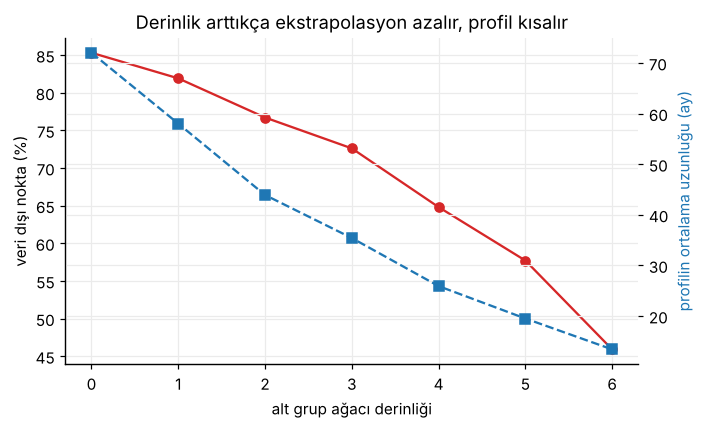

In [16]:
X_test = t_test[T_OZ].reset_index(drop=True)
naif_hepsi = X_test.loc[X_test.index.repeat(len(IZ))].assign(tenure=np.tile(IZ, len(X_test)))
satirlar = [{"derinlik": 0, "veri dışı (%)": 100 * veri_disi(naif_hepsi).mean(), "ortalama aralık (ay)": 72.0,
             "yaprak sayısı": 1}]
for d in [1, 2, 3, 4, 5, 6]:
    agac_d = alt_grup_agaci(t_egitim[T_OZ], "tenure", derinlik=d, min_yaprak=30)
    yap_egit = yaprak(agac_d, t_egitim[T_OZ], "tenure")
    araliklar = t_egitim.assign(_y=yap_egit).groupby("_y")["tenure"].agg(["min", "max"])
    yap_test = yaprak(agac_d, X_test, "tenure")
    parcalar = []
    for k, (lo, hi) in araliklar.iterrows():
        alt = X_test[yap_test == k]
        if len(alt):
            iz_k = np.arange(lo, hi + 1)
            parcalar.append(alt.loc[alt.index.repeat(len(iz_k))].assign(tenure=np.tile(iz_k, len(alt))))
    noktalar = pd.concat(parcalar)
    satirlar.append({"derinlik": d, "veri dışı (%)": 100 * veri_disi(noktalar).mean(),
                     "ortalama aralık (ay)": (araliklar["max"] - araliklar["min"]).reindex(yap_test).mean(),
                     "yaprak sayısı": len(araliklar)})
derinlik_tablo = pd.DataFrame(satirlar).set_index("derinlik").round(1)
print("Derinlik 0 = naif CP (alt grup yok)")
print(derinlik_tablo.to_string())

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(derinlik_tablo.index, derinlik_tablo["veri dışı (%)"], "o-", color=NAIF, label="veri dışı nokta (%)")
ax2 = ax.twinx()
ax2.plot(derinlik_tablo.index, derinlik_tablo["ortalama aralık (ay)"], "s--", color=ALTGRUP, label="ortalama aralık (ay)")
ax.set(xlabel="alt grup ağacı derinliği", ylabel="veri dışı nokta (%)")
ax2.set_ylabel("profilin ortalama uzunluğu (ay)", color=ALTGRUP)
ax.set_title("Derinlik arttıkça ekstrapolasyon azalır, profil kısalır")
fig.tight_layout()
goster(fig, "08_derinlik.png")

**Yorum.** Derinlik arttıkça veri dışı nokta oranı düzenli olarak azalıyor, ama bedeli profilin kısalması:
derinlik 6'da bir müşterinin profili ortalama yalnızca ~13 aylık bir aralığı kapsıyor. Bu
bir ödünleşim: **ekstrapolasyon** ile **açıklamanın kapsamı** arasında bir seçim yapmak gerekiyor. Makalenin kodunda
derinliğin ayar parametresi olarak 1–5 arasında denenmesinin nedeni de bu.

## 7. Sınırlamalar (savunma için)

1. **Profil kısalır.** Alt grup CP'si, müşterinin yaprağındaki aralığın dışında bir şey söylemez. "Bu müşteri 72 ay
   kalsa ne olur?" sorusuna cevap vermez; çünkü veride böyle bir müşteri yoktur ve dürüst cevap budur.
2. **Derinlik seçimi.** Sığ ağaç ekstrapolasyonu azaltmaz, derin ağaç profilleri çok kısaltır ve yaprakları küçültür.
   Makale de derinliği bir ayar parametresi olarak ele alıyor (bisiklet uygulamasında 1–5 arası derinlikler).
3. **CART ve transformation tree.** Makale dağılımın tamamına göre bölen transformation tree kullanıyor; CART yalnızca
   ortalamaya göre böler. Varyansı değişen ama ortalaması değişmeyen bağımlılıkları CART kaçırabilir.
4. **Eksen paralel bölünmeler.** `TotalCharges ≈ tenure × MonthlyCharges` gibi oransal bir ilişkiyi ağaç ancak
   basamaklarla yaklaşık yakalar. Elle düzeltilmiş CP bu yüzden bu veride daha keskin; ama ilişkiyi bilmeyi gerektirir.
5. **Veri dışı ölçütü benim seçimim.** En yakın komşu uzaklığının %99 kantili makalenin ölçütü değil; makale
   veri sadakatini MMD ile ölçüyor. Sayılar eşiğe bağlı.
6. **Nedensellik değil.** Alt grup CP'si de modelin davranışını açıklar, müşterinin gerçekten ne yapacağını değil.